In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/City_Air_Quality - City_Air_Quality.csv")

/tmp/ipykernel_1205/2440960775.py:4: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/City_Air_Quality - City_Air_Quality.csv")


In [11]:
print(df.head())
print(df.shape)
print(df.info())

  stn_code       sampling_date           state   location agency  \
0    150.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
1    151.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
2    152.0  February - M021990  Andhra Pradesh  Hyderabad    NaN   
3    150.0     March - M031990  Andhra Pradesh  Hyderabad    NaN   
4    151.0     March - M031990  Andhra Pradesh  Hyderabad    NaN   

                                 type  so2   no2  rspm  spm  \
0  Residential, Rural and other Areas  4.8  17.4   NaN  NaN   
1                     Industrial Area  3.1   7.0   NaN  NaN   
2  Residential, Rural and other Areas  6.2  28.5   NaN  NaN   
3  Residential, Rural and other Areas  6.3  14.7   NaN  NaN   
4                     Industrial Area  4.7   7.5   NaN  NaN   

  location_monitoring_station  pm2_5        date  
0                         NaN    NaN  1990-02-01  
1                         NaN    NaN  1990-02-01  
2                         NaN    NaN  1990-02-01  
3       

In [12]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
stn_code                        81314
sampling_date                       0
state                               0
location                            0
agency                          84561
type                             2957
so2                             21612
no2                             10530
rspm                            24452
spm                            106089
location_monitoring_station     16802
pm2_5                          210511
date                                2
dtype: int64


In [13]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

In [14]:
pollutants = [
    "so2",
    "no2",
    "rspm",
    "spm",
    "pm2_5"
]

In [15]:
for column in pollutants:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

In [16]:
for column in pollutants:
    df[column] = df[column].fillna(
        df[column].median()
    )

In [17]:
df["Pollution_Index"] = df[pollutants].mean(axis=1)

In [18]:
monthly_data = df.groupby(
    df["date"].dt.to_period("M")
)["Pollution_Index"].mean()

In [19]:
monthly_data.index = monthly_data.index.astype(str)

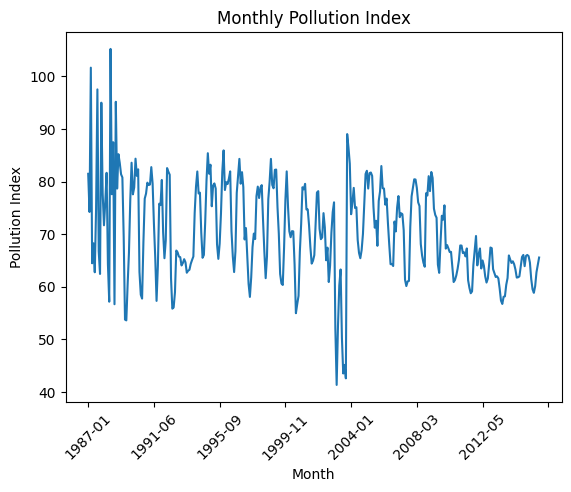

In [20]:
monthly_data.plot(kind="line")

plt.title("Monthly Pollution Index")
plt.xlabel("Month")
plt.ylabel("Pollution Index")
plt.xticks(rotation=45)
plt.show()

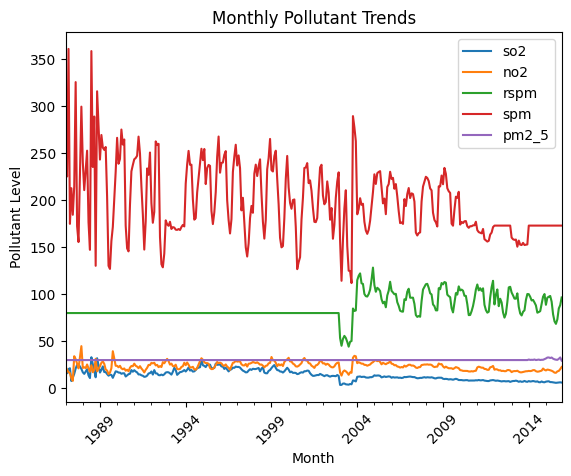

In [21]:
monthly_pollutants = df.groupby(
    df["date"].dt.to_period("M")
)[pollutants].mean()

monthly_pollutants.plot()

plt.title("Monthly Pollutant Trends")
plt.xlabel("Month")
plt.ylabel("Pollutant Level")
plt.xticks(rotation=45)
plt.legend()
plt.show()

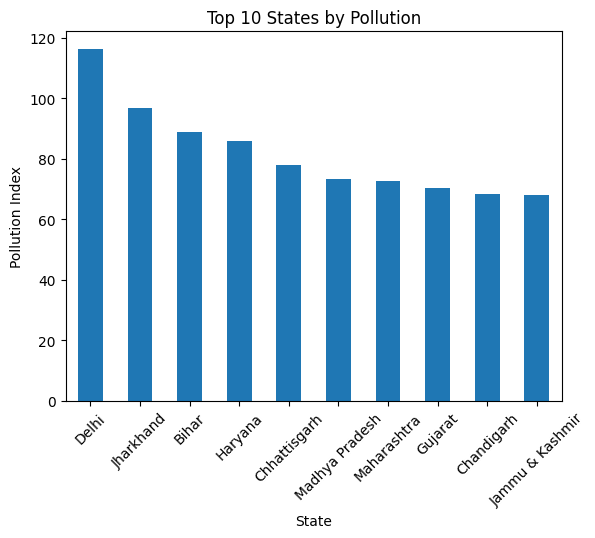

In [22]:
state_pollution = (
    df.groupby("state")["Pollution_Index"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

state_pollution.plot(kind="bar")

plt.title("Top 10 States by Pollution")
plt.xlabel("State")
plt.ylabel("Pollution Index")
plt.xticks(rotation=45)
plt.show()

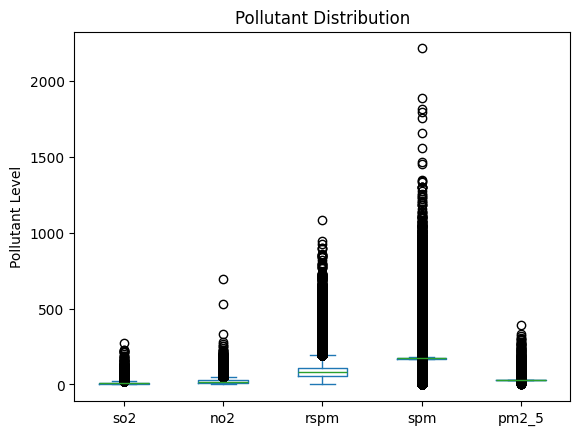

In [23]:
df[pollutants].plot(kind="box")

plt.title("Pollutant Distribution")
plt.ylabel("Pollutant Level")
plt.show()

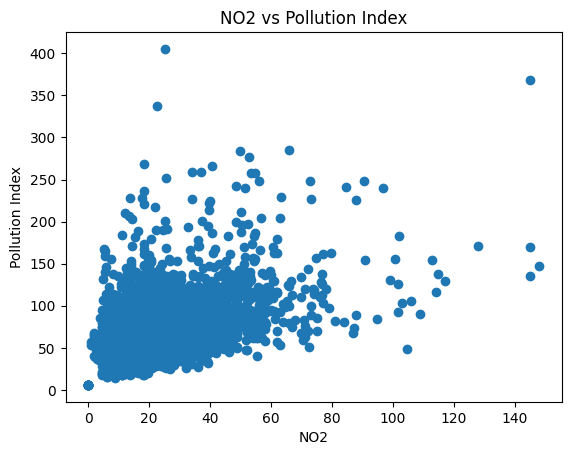

In [24]:
sample = df.sample(
    5000,
    random_state=42
)

plt.scatter(
    sample["no2"],
    sample["Pollution_Index"]
)

plt.title("NO2 vs Pollution Index")
plt.xlabel("NO2")
plt.ylabel("Pollution Index")
plt.show()

In [25]:
correlation = df[
    pollutants + ["Pollution_Index"]
].corr()

print("\nCorrelation:")
print(correlation)


Correlation:
                      so2       no2      rspm       spm     pm2_5  \
so2              1.000000  0.418486  0.162685  0.147308 -0.011147   
no2              0.418486  1.000000  0.408873  0.305316  0.058291   
rspm             0.162685  0.408873  1.000000  0.468131  0.093563   
spm              0.147308  0.305316  0.468131  1.000000 -0.004407   
pm2_5           -0.011147  0.058291  0.093563 -0.004407  1.000000   
Pollution_Index  0.272497  0.505968  0.791343  0.897439  0.077992   

                 Pollution_Index  
so2                     0.272497  
no2                     0.505968  
rspm                    0.791343  
spm                     0.897439  
pm2_5                   0.077992  
Pollution_Index         1.000000  


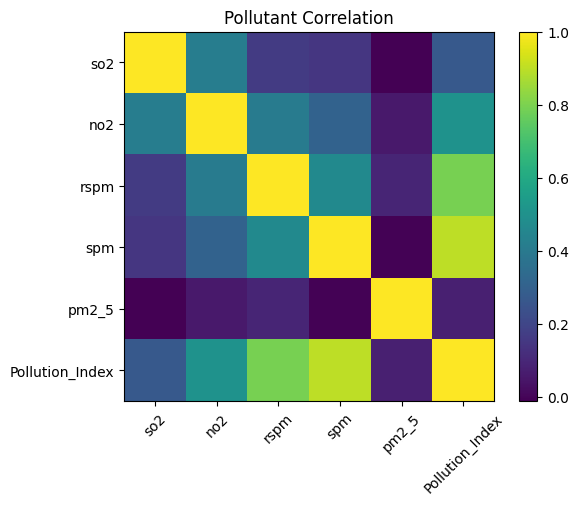

In [26]:
plt.imshow(correlation)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Pollutant Correlation")
plt.show()